# Real-world Data Wrangling
## Income and longevity: country-year evidence, 2000–2023

This notebook gathers two real public datasets, assesses two quality and two tidiness issues, validates the cleaning, and explores a descriptive research question. Raw responses and source metadata are preserved alongside the cleaned tables.

In [1]:
from pathlib import Path
import os, json, hashlib
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.parse import urlencode
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from wrangling import remove_missing_values, remove_missing_codes, flatten_life, merge_sources
ROOT = Path.cwd()
RAW = ROOT / 'data' / 'raw'
CLEAN = ROOT / 'data' / 'cleaned'
FIGURES = ROOT / 'figures'
for folder in (RAW, CLEAN, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
print('pandas:', pd.__version__, '| Working directory:', ROOT.name)

pandas: 2.3.3 | Working directory: Udacity_MS_Real_World_Data_Wrangling


In [2]:
# Reuse verified source bytes so reruns keep the same data vintage.
def acquire(url, filename):
    destination = RAW / filename
    manifest_path = RAW / 'provenance.json'
    manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    if not destination.exists() or os.environ.get('WRANGLING_REFRESH') == '1':
        request = Request(url, headers={'User-Agent': 'Udacity-Data-Wrangling/1.0'})
        with urlopen(request, timeout=90) as response:
            payload = response.read()
        destination.write_bytes(payload)
        manifest[filename] = {'url': url, 'retrieved_utc': datetime.now(timezone.utc).isoformat(),
                              'sha256': hashlib.sha256(payload).hexdigest(), 'bytes': len(payload)}
        manifest_path.write_text(json.dumps(manifest, indent=2) + '\n')
        print('Downloaded:', filename, len(payload), 'bytes')
    else:
        assert filename in manifest, 'Cached raw file needs provenance; rerun with WRANGLING_REFRESH=1'
        assert hashlib.sha256(destination.read_bytes()).hexdigest() == manifest[filename]['sha256']
        print('Verified cached source:', filename)
    return destination
print('Set WRANGLING_REFRESH=1 to download new source snapshots; default reruns verify the saved raw bytes.')

Set WRANGLING_REFRESH=1 to download new source snapshots; default reruns verify the saved raw bytes.


Dependencies are installed from `requirements-lock.txt` outside the notebook. A fresh kernel can run every cell without installation commands or a kernel restart.

## 1. Gather data

### 1.1 Problem statement

How is GDP per capita associated with life expectancy across countries in the latest shared year, and how did longevity change in four selected countries between 2000 and 2023? I combine an Our World in Data GDP CSV with World Bank life-expectancy API observations on country code and year. This is an exploratory association study, not a test of whether income causes longer lives.

The authoritative source metadata is saved in `data/raw/gdp_metadata.json`; source URLs, retrieval times and hashes are in `data/raw/provenance.json`. GDP is measured in purchasing-power-adjusted international dollars at 2021 prices; life expectancy is in years.

### 1.2 Two sources and two gathering methods

The next cells show an actual CSV file download and a parameterized JSON API request. Both raw datasets must exceed 500 observations and have at least two variables.

#### Dataset 1: GDP per capita — programmatic file download

I download Our World in Data's GDP-per-capita CSV because it supplies comparable country-year income measurements with stable join codes. `Entity`, `Code`, `Year`, and `GDP per capita` identify the location, time and income measure; the source also includes a region field that is not needed in the final analysis. This source is inflation- and purchasing-power-adjusted, so cross-country and temporal comparisons are more meaningful than comparisons of nominal exchange-rate dollars.

In [3]:
gdp_url = 'https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv?v=1&csvType=full&useColumnShortNames=false'
gdp_path = acquire(gdp_url, 'gdp_per_capita_owid.csv')
gdp_raw = pd.read_csv(gdp_path)
metadata_path = acquire('https://ourworldindata.org/grapher/gdp-per-capita-worldbank.metadata.json', 'gdp_metadata.json')
gdp_metadata = json.loads(metadata_path.read_text())
print('GDP shape:', gdp_raw.shape)
print(gdp_metadata['chart']['note'])
assert len(gdp_raw) > 500 and gdp_raw.shape[1] >= 2
display(gdp_raw.head())

Verified cached source: gdp_per_capita_owid.csv
Verified cached source: gdp_metadata.json
GDP shape: (7445, 5)
This data is expressed in international-$ at 2021 prices.


,Entity,Code,Year,GDP per capita,World region according to OWID
0,Afghanistan,AFG,2000,1617.8264,Asia
1,Afghanistan,AFG,2001,1454.1108,Asia
2,Afghanistan,AFG,2002,1774.3087,Asia
3,Afghanistan,AFG,2003,1815.9282,Asia
4,Afghanistan,AFG,2004,1776.9182,Asia


#### Dataset 2: life expectancy — JSON API access

I query the World Bank indicator API for life expectancy at birth (`SP.DYN.LE00.IN`) over 2000–2023, giving a health outcome related to the income question. Each record has a nested country object, country code, year (`date`) and measurement (`value`), plus indicator metadata. Regional aggregates are present too, so the final analysis must distinguish country-level observations from mixed geographic units.

In [4]:
parameters = urlencode({'format': 'json', 'date': '2000:2023', 'per_page': 20000})
life_url = 'https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN?' + parameters
life_path = acquire(life_url, 'life_expectancy_worldbank.json')
api_metadata, life_records = json.loads(life_path.read_text())
assert api_metadata['pages'] == 1 and len(life_records) == api_metadata['total']
life_raw = pd.DataFrame(life_records)
print('API metadata:', api_metadata)
print('Life-expectancy shape:', life_raw.shape)
assert len(life_raw) > 500 and life_raw.shape[1] >= 2
display(life_raw.head())

Verified cached source: life_expectancy_worldbank.json
API metadata: {'page': 1, 'pages': 1, 'per_page': 20000, 'total': 6384, 'sourceid': '2', 'lastupdated': '2026-10-08'}
Life-expectancy shape: (6384, 8)


,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,65.146228,,,0
1,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,64.487152,,,0
2,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,62.979999,,,0
3,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2020,63.766484,,,0
4,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2019,63.857261,,,0


#### Preserve raw sources

The CSV and JSON bytes are retained unmodified. The following fingerprints validate the cached inputs, rather than treating a successful download message as proof of provenance.

In [5]:
provenance = json.loads((RAW / 'provenance.json').read_text())
raw_hashes = {}
for filename, details in provenance.items():
    actual = hashlib.sha256((RAW / filename).read_bytes()).hexdigest()
    assert actual == details['sha256']
    raw_hashes[filename] = actual
display(pd.DataFrame(provenance).T[['retrieved_utc', 'bytes', 'sha256']])

,retrieved_utc,bytes,sha256
gdp_per_capita_owid.csv,2026-10-28T08:17:02.074233+00:00,276698,18018aea4360d625b274c8a773ebd7a54b7e22e1d79e19...
gdp_metadata.json,2026-10-28T08:17:02.796406+00:00,3400,0daf17d9665b5efc23df20a334a091a5fee9d27cb89721...
life_expectancy_worldbank.json,2026-10-28T08:17:05.118199+00:00,1457616,9fd82ce8e915667c3735f36bd8b478ad9eee2cd3fcd2a5...


## 2. Assess data

Each issue below has a displayed example and a programmatic assessment. Counts are calculated from the actual source snapshot, not inserted manually.

### Quality issue 1: missing life-expectancy measurements (completeness)

In [6]:
display(life_raw.loc[life_raw['value'].isna(), ['country', 'date', 'value']].head(8))

,country,date,value
840,"{'id': 'XY', 'value': 'Not classified'}",2023,NaN
841,"{'id': 'XY', 'value': 'Not classified'}",2022,NaN
842,"{'id': 'XY', 'value': 'Not classified'}",2021,NaN
843,"{'id': 'XY', 'value': 'Not classified'}",2020,NaN
844,"{'id': 'XY', 'value': 'Not classified'}",2019,NaN
845,"{'id': 'XY', 'value': 'Not classified'}",2018,NaN
846,"{'id': 'XY', 'value': 'Not classified'}",2017,NaN
847,"{'id': 'XY', 'value': 'Not classified'}",2016,NaN


In [7]:
# Count all null outcomes; a preview alone cannot establish their extent.
missing_values = int(life_raw['value'].isna().sum())
print('Missing essential measurements:', missing_values)
assert missing_values > 0

Missing essential measurements: 24


The analytical schema requires a numeric life-expectancy measurement, and a null outcome cannot be interpreted as zero. All 24 missing values belong to the 'Not classified' aggregate in this snapshot, not to measured individual countries; displaying affected records establishes that context, while the count establishes the extent. This is a completeness limitation for the intended analysis, not a claim that the provider's aggregate representation is corrupt.

### Quality issue 2: missing entity join identifiers (completeness)

In [8]:
missing_code_mask = life_raw['countryiso3code'].fillna('').str.strip().eq('')
display(life_raw.loc[missing_code_mask, ['country', 'countryiso3code', 'date', 'value']].head(8))

,country,countryiso3code,date,value
384,"{'id': 'XD', 'value': 'High income'}",,2023,80.149680
385,"{'id': 'XD', 'value': 'High income'}",,2022,79.426861
386,"{'id': 'XD', 'value': 'High income'}",,2021,78.798155
387,"{'id': 'XD', 'value': 'High income'}",,2020,79.204141
388,"{'id': 'XD', 'value': 'High income'}",,2019,80.199262
389,"{'id': 'XD', 'value': 'High income'}",,2018,79.965975
390,"{'id': 'XD', 'value': 'High income'}",,2017,79.853623
391,"{'id': 'XD', 'value': 'High income'}",,2016,79.724311


In [9]:
# Show overlap so sequential exclusions do not count the same row twice.
missing_codes = int(missing_code_mask.sum())
print('Missing country codes:', missing_codes)
print('Overlap with missing measurements:', int((missing_code_mask & life_raw['value'].isna()).sum()))
display(life_raw.loc[missing_code_mask, 'country'].map(lambda x: x['value']).value_counts())
assert missing_codes > 0

Missing country codes: 120
Overlap with missing measurements: 24


country
High income            24
Low income             24
Lower middle income    24
Not classified         24
Upper middle income    24
Name: count, dtype: int64

The analytical schema requires a nonempty entity code to join on code and year; blank identifiers violate that requirement even where a measurement exists. Here the affected entities are four income-group aggregates and 'Not classified', for which absent ISO-country codes may be intentional API semantics, not erroneous country records. A whitespace-aware mask and entity counts distinguish those records, which are excluded rather than assigned guessed country codes. These two quality issues are completeness problems relative to this analysis; an evaluator may prefer issues affecting individual-country measurements, so this scope limitation is explicit.

### Tidiness issue 1: multiple variables inside JSON object cells

In [10]:
display(life_raw[['country', 'indicator', 'date']].head(3))

,country,indicator,date
0,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...","{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...",2023
1,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...","{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...",2022
2,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...","{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...",2021


In [11]:
# Detect nested values by type rather than assuming the preview is representative.
nested_columns = [column for column in life_raw if life_raw[column].map(lambda x: isinstance(x, (dict, list))).any()]
print('Columns containing nested objects:', nested_columns)
print('Country fields:', sorted(life_raw.iloc[0]['country']))
print('Indicator fields:', sorted(life_raw.iloc[0]['indicator']))
assert {'country', 'indicator'}.issubset(nested_columns)

Columns containing nested objects: ['indicator', 'country']
Country fields: ['id', 'value']
Indicator fields: ['id', 'value']


A country cell contains both an identifier and a label, so separate variables are not yet separate columns in the analysis table. Inspecting a displayed cell reveals the structure, and type/field checks confirm this is systematic rather than a display artifact; normalization will expose atomic fields.

### Tidiness issue 2: a country-year observation split across sources

In [12]:
display(gdp_raw[['Entity', 'Code', 'Year', 'GDP per capita']].head(3))
display(life_raw[['countryiso3code', 'date', 'value']].tail(3))

,Entity,Code,Year,GDP per capita
0,Afghanistan,AFG,2000,1617.8264
1,Afghanistan,AFG,2001,1454.1108
2,Afghanistan,AFG,2002,1774.3087


,countryiso3code,date,value
6381,ZWE,2002,45.938
6382,ZWE,2001,44.525
6383,ZWE,2000,46.034


In [13]:
# Match identifiers and years, not display names that may vary between sources.
gdp_keys = set(zip(gdp_raw['Code'], gdp_raw['Year']))
life_keys = set(zip(life_raw['countryiso3code'], life_raw['date'].astype(int)))
print('Shared country-year keys:', len(gdp_keys & life_keys))
print('GDP duplicates:', int(gdp_raw.duplicated(['Code', 'Year']).sum()))
print('Life duplicates:', int(life_raw.duplicated(['countryiso3code', 'date']).sum()))
assert len(gdp_keys & life_keys) > 500

Shared country-year keys: 4705
GDP duplicates: 0
Life duplicates: 96


The same country-year observational unit has income in one table and longevity in another. A key-intersection check proves the tables can be combined; an audited one-to-one join will produce one observation per row without multiplying records. Duplicate checks expose ambiguity before the join.

## 3. Clean data

The raw sources stay immutable. Each transformation below has a separate validation; row exclusions are disclosed instead of silently imputed.

In [14]:
gdp_work = gdp_raw.copy(deep=True)
life_work = life_raw.copy(deep=True)
print('Raw and working frames created separately.')

Raw and working frames created separately.


### Quality issue 1: remove missing essential measurements

In [15]:
# Do not impute essential outcomes for an aggregate with no reported measurement.
measured = remove_missing_values(life_work)
excluded_values = life_work.loc[life_work['value'].isna()].copy()

In [16]:
assert measured['value'].notna().all()
assert len(measured) == len(life_work) - missing_values
print('Rows before:', len(life_work), '| after:', len(measured), '| removed:', missing_values)

Rows before: 6384 | after: 6360 | removed: 24


I use complete cases for the essential outcome rather than inventing life-expectancy values. In this snapshot the 24 exclusions are all 'Not classified' aggregates, so this step removes no individual-country measurement; excluded records are saved to make that check auditable. Complete-case analysis could still introduce selection bias if future missingness affects countries systematically.

### Quality issue 2: remove records without join identifiers

In [17]:
# Remove remaining unjoinable aggregates after null outcomes to avoid double-counting.
identified = remove_missing_codes(measured)
excluded_codes = measured.loc[measured['countryiso3code'].fillna('').str.strip().eq('')].copy()

In [18]:
assert identified['countryiso3code'].fillna('').str.strip().ne('').all()
assert len(identified) + len(excluded_codes) == len(measured)
print('Remaining missing-code rows removed:', len(excluded_codes), '| retained:', len(identified))

Remaining missing-code rows removed: 96 | retained: 6264


The remaining blank-code rows are income-group aggregates outside the country/economy unit of analysis, and assigning them country codes would create misleading links. The exclusion is computed after removing missing outcomes, so overlapping incomplete fields are not double-counted; no individual-country observation is removed by these two steps in this snapshot.

### Tidiness issue 1: normalize nested objects into atomic fields

In [19]:
# Expose atomic country fields before selecting the variables used in the analysis.
life_tidy = flatten_life(identified.to_dict('records'))
display(life_tidy.head())

,country_code,country,year,life_expectancy_years
0,AFE,Africa Eastern and Southern,2023,65.146228
1,AFE,Africa Eastern and Southern,2022,64.487152
2,AFE,Africa Eastern and Southern,2021,62.979999
3,AFE,Africa Eastern and Southern,2020,63.766484
4,AFE,Africa Eastern and Southern,2019,63.857261


In [20]:
assert not life_tidy.map(lambda x: isinstance(x, (dict, list))).any().any()
assert life_tidy.year.dtype.kind in 'iu'
assert life_tidy.life_expectancy_years.between(0, 120).all()
assert not life_tidy.duplicated(['country_code', 'year']).any()
print('Atomic fields and typed years validated:', life_tidy.shape)

Atomic fields and typed years validated: (6264, 4)


`json_normalize` separates nested fields before selecting country code, label, year and outcome. Indicator labels and response-status metadata are removed as irrelevant variables, not counted as additional data-quality fixes.

### Tidiness issue 2: join the country-year observational unit

In [21]:
# Validate one-to-one keys and audit unmatched rows before retaining paired observations.
combined, join_audit = merge_sources(gdp_work, life_tidy)
print('Outer-join audit (before geographic scope selection):', join_audit)
display(combined.head())

Outer-join audit (before geographic scope selection): {'both': 4705, 'right_only': 1559, 'left_only': 328}


,country_code,country,year,gdp_per_capita_ppp,life_expectancy_years
0,ABW,Aruba,2000,37618.992,72.939
1,ABW,Aruba,2001,38827.470,73.044
2,ABW,Aruba,2002,38195.316,73.135
3,ABW,Aruba,2003,38182.390,73.236
4,ABW,Aruba,2004,40101.790,73.223


In [22]:
assert len(combined) == join_audit['both']
assert not combined.duplicated(['country_code', 'year']).any()
assert combined[['gdp_per_capita_ppp', 'life_expectancy_years']].notna().all().all()
print('Validated one-to-one matched observations:', len(combined))

Validated one-to-one matched observations: 4705


An outer join reports unmatched keys; only paired observations enter the analysis. `validate='one_to_one'` rejects duplicate keys instead of silently multiplying rows, and the year window is aligned to the API request.

### Final scope and variable selection

OWID uses special codes for its aggregates, whereas the World Bank uses different aggregate codes, so these do not match in this snapshot. I check for residual non-three-letter codes after the join; zero removals is a valid audit result, not an additional claimed cleaning issue. This regex is only a source-specific guard, not a universal ISO-country validator; the result covers countries and separately reported economies, with five useful variables and one country-year per row.

| Variable | Type | Meaning and units |
|---|---|---|
| `country_code` | string | Source entity identifier; first part of the unique key |
| `country` | string | Country/economy label from the GDP source |
| `year` | integer | Calendar year, 2000–2023; second part of the unique key |
| `gdp_per_capita_ppp` | float | PPP international dollars per person at 2021 prices |
| `life_expectancy_years` | float | Life expectancy at birth, years |

The pair `(country_code, year)` uniquely identifies an observation; `country` is a display label, not a join key.

In [23]:
# This snapshot-specific guard is not a general country-registry lookup.
aggregate_mask = ~combined.country_code.str.fullmatch(r'[A-Z]{3}', na=False)
display(combined.loc[aggregate_mask, ['country_code', 'country']].drop_duplicates())
aggregate_rows = int(aggregate_mask.sum())
final = combined.loc[~aggregate_mask].copy().reset_index(drop=True)
assert final.shape[1] >= 4 and len(final) > 500
assert final.notna().all().all()
assert final.gdp_per_capita_ppp.gt(0).all()
assert not final.duplicated(['country_code', 'year']).any()
print('Final shape:', final.shape, '| countries/economies:', final.country_code.nunique())
print('Year coverage:', final.year.min(), final.year.max(), '| matched aggregate rows removed:', aggregate_rows)
display(final.describe(include='all'))

,country_code,country


Final shape: (4705, 5) | countries/economies: 198
Year coverage: 2000 2023 | matched aggregate rows removed: 0


,country_code,country,year,gdp_per_capita_ppp,life_expectancy_years
count,4705,4705,4705.000000,4705.000000,4705.000000
unique,198,198,NaN,NaN,NaN
top,ABW,Aruba,NaN,NaN,NaN
freq,24,24,NaN,NaN,NaN
mean,NaN,NaN,2011.567056,23769.869353,70.493687
std,NaN,NaN,6.907416,25353.115231,8.790583
min,NaN,NaN,2000.000000,702.850100,14.665000
25%,NaN,NaN,2006.000000,5064.287600,64.963000
50%,NaN,NaN,2012.000000,14259.366000,72.005000
75%,NaN,NaN,2018.000000,35115.380000,77.034146


## 4. Store data

Source payloads remain under `data/raw/`; typed analytical CSVs and excluded-row audits are stored separately under `data/cleaned/`. The JSON audit records the row accounting and dataset definitions.

In [24]:
life_tidy.to_csv(CLEAN / 'life_expectancy_tidy.csv', index=False)
gdp_work.to_csv(CLEAN / 'gdp_source_table.csv', index=False)
final.to_csv(CLEAN / 'country_year_income_longevity.csv', index=False)
excluded_values.to_json(CLEAN / 'excluded_missing_measurements.json', orient='records', indent=2)
excluded_codes.to_json(CLEAN / 'excluded_missing_identifiers.json', orient='records', indent=2)
audit = {'gdp_source_rows': len(gdp_raw), 'life_source_rows': len(life_raw),
         'missing_measurements': missing_values, 'missing_codes_initial': missing_codes,
         'missing_codes_removed_after_measurements': len(excluded_codes),
         'join': join_audit, 'aggregate_rows_removed': aggregate_rows,
         'final_rows': len(final), 'final_variables': list(final),
         'gdp_unit': 'PPP international dollars at 2021 prices', 'life_unit': 'years'}
(CLEAN / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2) + '\n')
round_trip = pd.read_csv(CLEAN / 'country_year_income_longevity.csv')
pd.testing.assert_frame_equal(final, round_trip, check_exact=False)
for filename, expected in raw_hashes.items():
    assert hashlib.sha256((RAW / filename).read_bytes()).hexdigest() == expected
print(json.dumps(audit, indent=2))
print('CSV round trip and raw-source immutability passed.')

{
  "gdp_source_rows": 7445,
  "life_source_rows": 6384,
  "missing_measurements": 24,
  "missing_codes_initial": 120,
  "missing_codes_removed_after_measurements": 96,
  "join": {
    "both": 4705,
    "right_only": 1559,
    "left_only": 328
  },
  "aggregate_rows_removed": 0,
  "final_rows": 4705,
  "final_variables": [
    "country_code",
    "country",
    "year",
    "gdp_per_capita_ppp",
    "life_expectancy_years"
  ],
  "gdp_unit": "PPP international dollars at 2021 prices",
  "life_unit": "years"
}
CSV round trip and raw-source immutability passed.


## 5. Answer the research question

### Income and longevity: latest-year association and selected-country changes

The cross-section uses the latest shared year, while the second plot follows Brazil, China, India and the United States. These countries were selected in advance for contrasting income and geographic contexts, not as a representative sample; no causal identification is attempted.

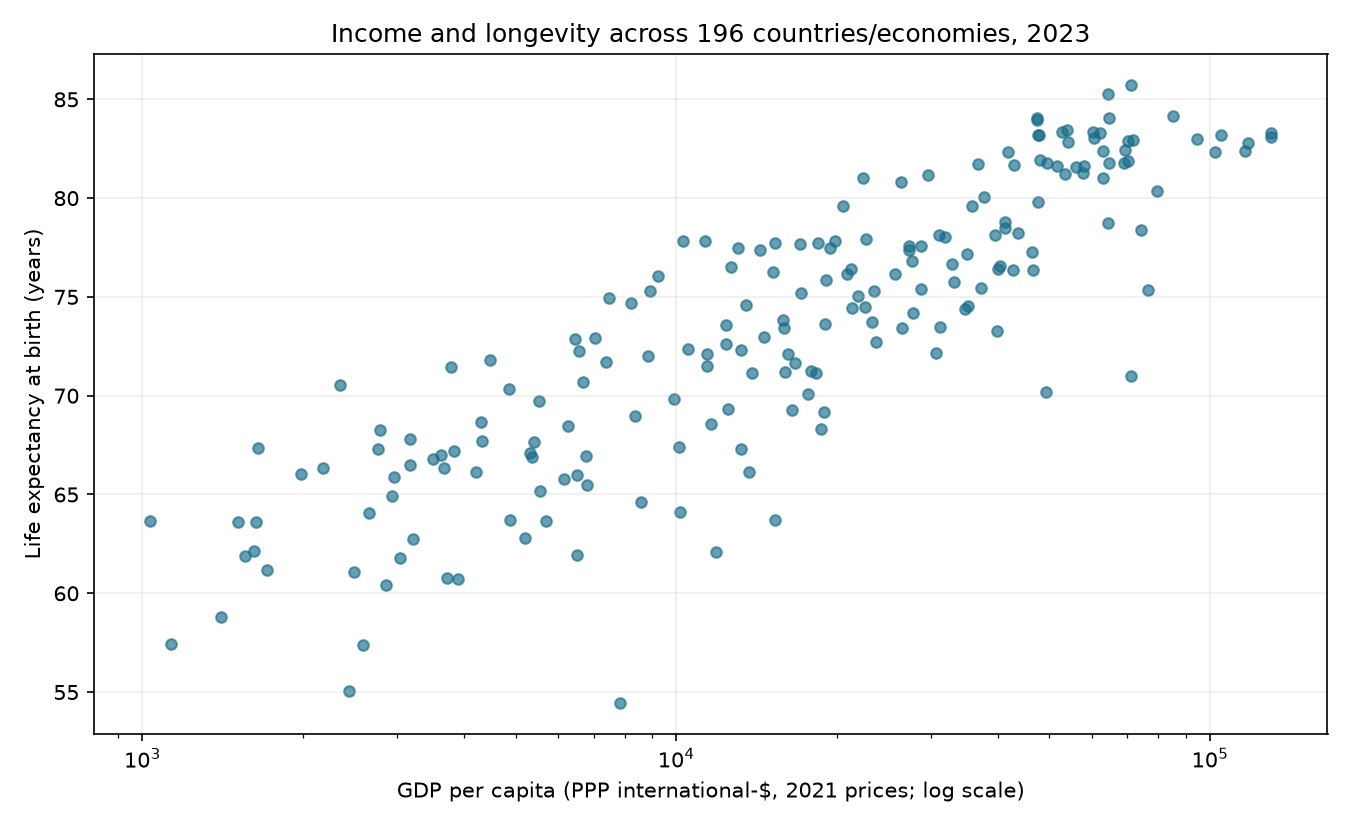

2023: n=196; Pearson r(log10 GDP, life expectancy)=0.863


In [25]:
latest_year = int(final.year.max())
latest = final.loc[final.year.eq(latest_year)]
correlation = float(np.log10(latest.gdp_per_capita_ppp).corr(latest.life_expectancy_years))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(latest.gdp_per_capita_ppp, latest.life_expectancy_years, alpha=0.65, s=26, color='#176b87')
ax.set_xscale('log')
ax.set(xlabel='GDP per capita (PPP international-$, 2021 prices; log scale)', ylabel='Life expectancy at birth (years)', title=f'Income and longevity across {len(latest)} countries/economies, {latest_year}')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / 'income_longevity_scatter.png', dpi=150)
display(Image(filename=str(FIGURES / 'income_longevity_scatter.png')))
plt.close(fig)
print(f'{latest_year}: n={len(latest)}; Pearson r(log10 GDP, life expectancy)={correlation:.3f}')

In 2023, the 196 observed countries/economies show a strong positive association between log income and life expectancy (Pearson r = 0.863), with considerable dispersion at similar incomes. This is descriptive rather than causal: health systems, education, inequality and measurement differences are not controlled for.

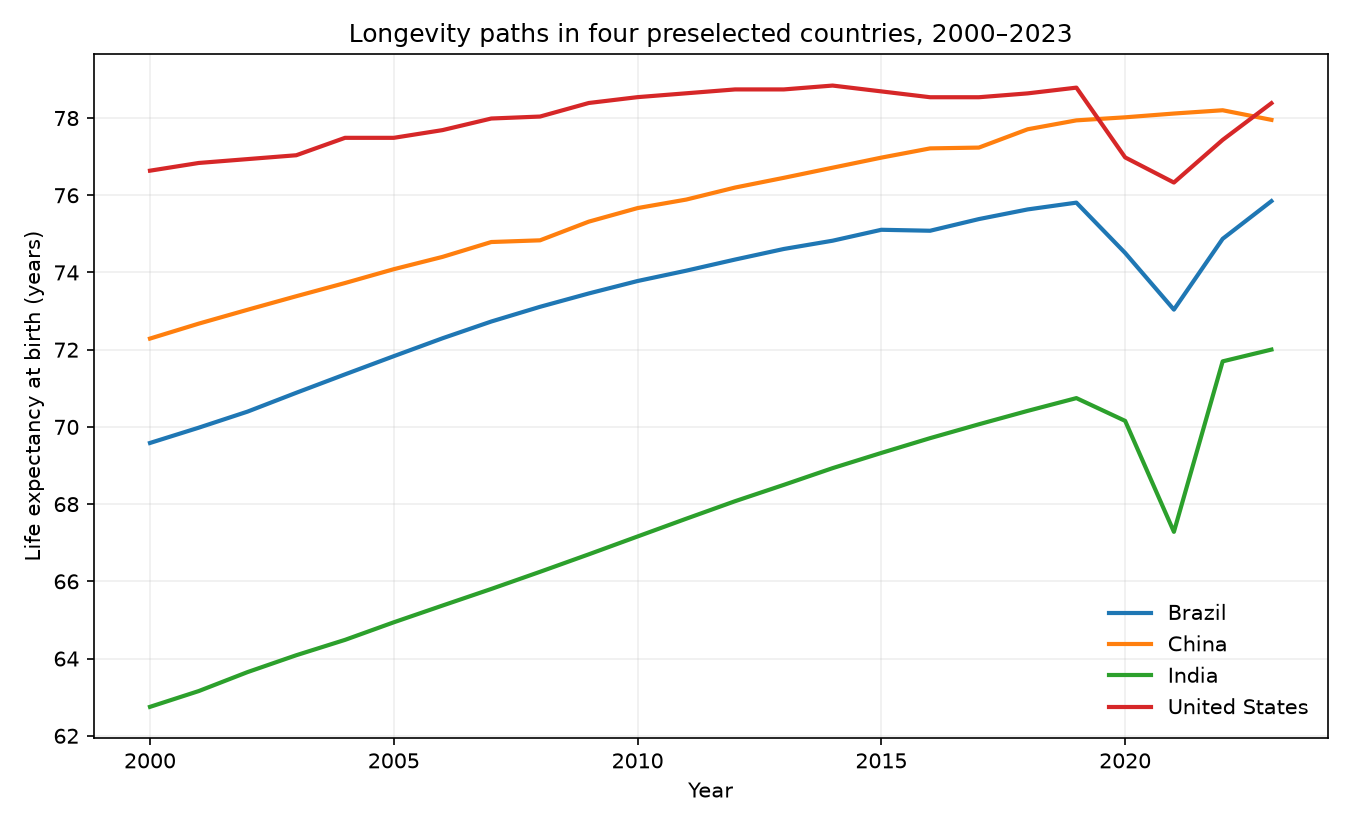

,"Change in life expectancy, 2000–2023 (years)"
country,
Brazil,6.26
China,5.67
India,9.25
United States,1.75


In [26]:
selected = ['BRA', 'CHN', 'IND', 'USA']
trajectories = final.loc[final.country_code.isin(selected)]
fig, ax = plt.subplots(figsize=(9, 5.5))
for code in selected:
    country = trajectories.loc[trajectories.country_code.eq(code)].sort_values('year')
    assert len(country) >= 20
    ax.plot(country.year, country.life_expectancy_years, label=country.country.iloc[0], linewidth=2)
ax.set(xlabel='Year', ylabel='Life expectancy at birth (years)', title='Longevity paths in four preselected countries, 2000–2023')
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / 'selected_country_longevity.png', dpi=150)
display(Image(filename=str(FIGURES / 'selected_country_longevity.png')))
plt.close(fig)
changes = trajectories.pivot(index='country', columns='year', values='life_expectancy_years')
display((changes[2023] - changes[2000]).round(2).rename('Change in life expectancy, 2000–2023 (years)').to_frame())

From 2000 to 2023, life expectancy increased by 9.25 years in India, 6.26 in Brazil, 5.67 in China and 1.75 in the United States, despite pandemic-era reversals. These preselected trajectories provide temporal context, but do not establish that income changes explain the health changes.

### 5.2 Reflection and next steps

The project converted heterogeneous CSV and nested API observations into a reproducible country-year table with an explicit exclusion and join audit. Complete-case selection, differences in source vintages, and international measurement uncertainty limit comparability. With more time, I would add health spending, education and inequality indicators, examine missingness by region, and use longitudinal methods with uncertainty estimates rather than interpret a cross-sectional correlation as causal.